# Stage 2 — Joint threshold analysis for CTC and ignition

This notebook follows the independently replicated Stage 1 candidate window: **K = 2–3 rad/s** and **stimulus_drive = 0.12–0.14**. It uses a two-node S→W model and the same GNW E/I mean-field update interface as Stage 1. The experiments add explicit, provisional attention, recurrence, competition, and resource mechanisms so their effects can be isolated.

The six experiments are implemented below. Long scans are opt-in: set `RUN_SCANS = True` in the setup cell, then run one experiment at a time. Begin with `N_SEEDS = 5` for a quick preview; use 50–100 paired seeds for final estimates.

**Scope:** this is a controlled two-node mechanistic experiment, not yet a result from the full 40-area GNW network. `stimulus_drive` is a model input unit, not pA. Added coefficients (`g_task`, `alpha`, competition and resource parameters) are experimental operationalizations and should be documented as such.


## Step 0 — imports, parameter window, and scan controls

The baseline uses the Stage 1 stimulus window and ignition rule (W mean rate ≥ 20 Hz for at least 50 ms). Weak and strong coupling are both chosen inside the replicated interval.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = Path.cwd()
if not (project_root / 'gnw_mean_field.py').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
if str(project_root / 'project_experiment') not in sys.path:
    sys.path.insert(0, str(project_root / 'project_experiment'))

from gnw_mean_field import GNWMeanFieldParameters, initialize_mean_field_state, mean_field_step

OUT = project_root / 'project_experiment'
OUT.mkdir(exist_ok=True)
BASE = {
    'duration_ms': 800.0, 'dt_ms': 1.0,
    'stim_on_ms': 50.0, 'stim_off_ms': 500.0,
    'stimulus_drive': 0.13,
    'g_sw': 0.95, 'phase_gate_strength': 0.5,
    'K_rad_s': 2.5,  # within Stage 1 replicated 2–3 rad/s window
    'alpha': 0.05,   # Stage 1 baseline local recurrence
    'phase_frequency_s_hz': 10.0, 'phase_frequency_w_hz': 10.3,
    'phase_diffusion_rad_sqrt_s': 0.15, 'phase_offset_rad': 0.0,
    'ignition_threshold_hz': 20.0, 'ignition_duration_ms': 50.0,
    'phase_window_ms': 50.0,
    'task_gain': 0.0, 'attention_mode': 'both',
    'decay_mode': 'none', 'task_decay_tau_ms': 100.0,
    'competitor_on_ms': 200.0, 'competitor_level': 1.0,
    'competition_inhibition': 0.8,
    'resource_depletion_per_s': 2.0, 'resource_activity_threshold_hz': 15.0,
}
K_WEAK, K_STRONG = 2.0, 3.0
VALIDATED_STIMULI = [0.12, 0.13, 0.14]
RUN_SCANS = False
N_SEEDS = 5       # preview; raise to 50–100 for final Monte Carlo summaries
BASE_SEEDS = np.arange(1, N_SEEDS + 1)
print('Project:', project_root)
print('Validated window: K=2–3 rad/s; stimulus_drive=0.12–0.14')
print('Long scans enabled:', RUN_SCANS, '| seeds per condition:', N_SEEDS)


Project: D:\Project\pythonProject\atoum-master
Validated window: K=2–3 rad/s; stimulus_drive=0.12–0.14
Long scans enabled: False | seeds per condition: 5


## Shared simulation model

`g_task` is an abstract attentional gain. Its channel is explicit: `intensity` scales sensory drive; `synchrony` increases phase coupling K; `both` applies both effects. `alpha` is the local W→W recurrent excitatory feedback coefficient. The rate equations and local inhibition still use `gnw_mean_field.mean_field_step`.

The simulation returns the W rate, phase difference/PLV, effective attention gain, ignition outcome, and latency. Different mechanisms are exposed as function arguments rather than silently changing the baseline.

In [2]:
def _wrap_phase(x):
    return (x + np.pi) % (2 * np.pi) - np.pi


def _first_ignition(time_ms, rate_hz, threshold_hz, duration_ms, after_ms):
    dt = float(np.median(np.diff(time_ms)))
    n = max(1, int(np.ceil(duration_ms / dt)))
    valid = (rate_hz >= threshold_hz) & (time_ms >= after_ms)
    if n > len(valid):
        return False, np.nan, np.nan
    hits = np.convolve(valid.astype(int), np.ones(n, dtype=int), mode='valid')
    starts = np.flatnonzero(hits == n)
    if not starts.size:
        return False, np.nan, np.nan
    idx = int(starts[0])
    return True, float(time_ms[idx] - after_ms), float(time_ms[idx])


def phase_lock_acquisition(time_ms, theta_s, theta_w, *, window_ms=100.0, stable_ms=100.0, slope_limit_rad_s=0.75):
    """First sustained interval with a nearly stationary unwrapped phase difference.

    This avoids the startup bias of a short-window PLV magnitude. The slope limit
    is an operational criterion; sensitivity should be checked in the final scan.
    """
    dt=float(np.median(np.diff(time_ms)))
    win=max(3,int(round(window_ms/dt)))
    stable=max(1,int(round(stable_ms/dt)))
    delta=np.unwrap(np.asarray(theta_w)-np.asarray(theta_s))
    if len(delta)<win+stable-1:
        return np.nan
    windows=np.lib.stride_tricks.sliding_window_view(delta,win)
    x=(np.arange(win)-(win-1)/2)*dt/1000.0
    slopes=(windows@x)/np.dot(x,x)
    valid=np.abs(slopes)<=slope_limit_rad_s
    counts=np.convolve(valid.astype(int),np.ones(stable,dtype=int),mode='valid')
    starts=np.flatnonzero(counts==stable)
    return float(time_ms[starts[0]+win-1]) if starts.size else np.nan


def simulate_joint(*, seed=1, params=None, stimulus_schedule=None,
                   attention_mode=None, decay_mode=None, phase_on=True):
    p = {**BASE, **(params or {})}
    mode = attention_mode or p['attention_mode']
    decay = decay_mode or p['decay_mode']
    if mode not in {'none', 'intensity', 'synchrony', 'both'}:
        raise ValueError('attention_mode must be none/intensity/synchrony/both')
    if decay not in {'none', 'target_decay', 'competition', 'resource'}:
        raise ValueError('unknown decay_mode')
    dt = float(p['dt_ms'])
    if stimulus_schedule is None:
        time_ms = np.arange(0, p['duration_ms'] + 0.5 * dt, dt)
        stimulus = np.where((time_ms >= p['stim_on_ms']) & (time_ms < p['stim_off_ms']),
                            p['stimulus_drive'], 0.0)
    else:
        stimulus = np.asarray(stimulus_schedule, dtype=float)
        time_ms = np.arange(stimulus.size, dtype=float) * dt
    n = len(time_ms)
    rng = np.random.default_rng(int(seed))
    theta_s = np.empty(n); theta_w = np.empty(n)
    theta_s[0], theta_w[0] = rng.uniform(-np.pi, np.pi, size=2)
    mf = GNWMeanFieldParameters()
    rE = np.empty((n, 2)); rI = np.empty((n, 2))
    sE = np.empty((n, 2)); sI = np.empty((n, 2))
    rE[0], rI[0], sE[0], sI[0] = initialize_mean_field_state(2, mf)
    plv = np.zeros(n); align = np.zeros(n); gtask_trace = np.zeros(n)
    gsw_trace = np.zeros(n); dtheta = np.zeros(n)
    omega_s = 2*np.pi*float(p['phase_frequency_s_hz'])
    omega_w = 2*np.pi*float(p['phase_frequency_w_hz'])
    noise = float(p['phase_diffusion_rad_sqrt_s']) * np.sqrt(dt/1000)
    win = max(1, int(round(float(p['phase_window_ms'])/dt)))
    ring = np.zeros(win, dtype=complex); ring_sum = 0j
    above_ms = 0.0; active_total_ms = 0.0; ignition_event_ms = np.nan
    after_trigger_gain = float(p['task_gain'])

    for k in range(1, n):
        t = time_ms[k-1]
        delta = _wrap_phase(theta_w[k-1] - theta_s[k-1] - float(p['phase_offset_rad']))
        in_task = stimulus[k-1] > 0
        gain = float(p['task_gain']) if in_task else 0.0
        # Dynamic attention gain: task success triggers decay; a competitor steals
        # gain in proportion to the fraction not suppressed; resource use accumulates
        # only while W remains above ignition threshold.
        if decay == 'target_decay' and np.isfinite(ignition_event_ms):
            gain = after_trigger_gain * np.exp(-max(0.0, t-ignition_event_ms)/float(p['task_decay_tau_ms']))
        elif decay == 'competition' and t >= float(p['competitor_on_ms']):
            steal = float(p['competitor_level']) * (1-float(p['competition_inhibition']))
            gain = gain / (1+steal)
        elif decay == 'resource':
            gain = gain * np.exp(-float(p['resource_depletion_per_s'])*active_total_ms/1000.0)
        gtask_trace[k] = gain

        K_eff = float(p['K_rad_s'])
        if mode in {'synchrony', 'both'}:
            K_eff *= (1+gain)
        if phase_on:
            theta_s[k] = theta_s[k-1] + (omega_s + K_eff*np.sin(delta))*dt/1000 + noise*rng.standard_normal()
            theta_w[k] = theta_w[k-1] + (omega_w - K_eff*np.sin(delta))*dt/1000 + noise*rng.standard_normal()
        else:
            theta_s[k] = theta_s[k-1] + omega_s*dt/1000 + noise*rng.standard_normal()
            theta_w[k] = theta_w[k-1] + omega_w*dt/1000 + noise*rng.standard_normal()
        theta_s[k] = _wrap_phase(theta_s[k]); theta_w[k] = _wrap_phase(theta_w[k])
        delta = _wrap_phase(theta_w[k]-theta_s[k]-float(p['phase_offset_rad']))
        dtheta[k] = delta
        align[k] = 0.5*(1+np.cos(delta))
        ri = (k-1) % win
        ring_sum -= ring[ri]; ring[ri] = np.exp(1j*delta); ring_sum += ring[ri]
        plv[k] = abs(ring_sum/min(k,win))

        intensity_gain = gain if mode in {'intensity','both'} else 0.0
        sensory_input = stimulus[k-1]*(1+intensity_gain)
        g_sw_eff = float(p['g_sw'])*(1+float(p['phase_gate_strength'])*align[k]) if phase_on else float(p['g_sw'])
        gsw_trace[k] = g_sw_eff
        input_e = np.zeros(2)
        input_e[0] = sensory_input
        input_e[1] = float(p['alpha'])*sE[k-1,1] + g_sw_eff*sE[k-1,0]
        rE[k],rI[k],sE[k],sI[k] = mean_field_step(
            rE[k-1],rI[k-1],sE[k-1],sI[k-1],input_e,dt,mf)
        if rE[k,1] >= float(p['resource_activity_threshold_hz']):
            active_total_ms += dt
        if rE[k,1] >= float(p['ignition_threshold_hz']):
            above_ms += dt
            if above_ms >= float(p['ignition_duration_ms']) and not np.isfinite(ignition_event_ms):
                ignition_event_ms = time_ms[k] - float(p['ignition_duration_ms']) + dt
        else:
            above_ms = 0.0

    onset = float(p.get('ignition_after_ms', p['stim_on_ms']))
    ignited, latency, onset_time = _first_ignition(
        time_ms,rE[:,1],float(p['ignition_threshold_hz']),float(p['ignition_duration_ms']),onset)
    # Lock acquisition uses sustained phase-difference stationarity, not short-window PLV magnitude.
    lock_time = phase_lock_acquisition(time_ms,theta_s,theta_w)
    lock_latency = max(0.0,lock_time-onset) if np.isfinite(lock_time) else np.nan
    return {'time_ms':time_ms,'stimulus':stimulus,'r_s_hz':rE[:,0],'r_w_hz':rE[:,1],
            'theta_s':theta_s,'theta_w':theta_w,'delta_phase':dtheta,'plv':plv,
            'alignment':align,'g_task':gtask_trace,'g_sw':gsw_trace,
            'ignited':bool(ignited),'ignition_latency_ms':latency,
            'ignition_onset_ms':onset_time,'phase_lock_latency_ms':lock_latency,'phase_lock_time_ms':lock_time,
            'parameters':p}


def summarize_trials(rows):
    frame = pd.DataFrame(rows)
    return frame.groupby(['condition'], dropna=False).agg(
        n=('seed','count'), ignition_probability=('ignited','mean'),
        mean_latency_ms=('latency_ms','mean'), latency_variance_ms2=('latency_ms','var'),
        mean_R=('mean_R','mean'), mean_peak_W_hz=('peak_W_hz','mean')).reset_index()


def one_trial_row(result, condition, seed):
    p=result['parameters']; stim=(result['time_ms']>=p['stim_on_ms']) & (result['time_ms']<p['stim_off_ms'])
    after=result['time_ms']>=p['stim_off_ms']
    return {'condition':condition,'seed':int(seed),'ignited':result['ignited'],
            'latency_ms':result['ignition_latency_ms'],
            'mean_R':float(abs(np.exp(1j*result['delta_phase'][stim]).mean())) if stim.any() else np.nan,
            'peak_W_hz':float(np.max(result['r_w_hz'])),
            'mean_W_after_hz':float(result['r_w_hz'][after].mean()) if after.any() else np.nan,
            'W_above_threshold_after_ms':float(np.sum(result['r_w_hz'][after]>=p['ignition_threshold_hz'])*p['dt_ms'])}

print('Shared Stage 2 simulator defined.')


Shared Stage 2 simulator defined.


## Experiment 2.1 — strength × synchrony threshold map

Scan sensory drive and the **phase-gate setting** (the model knob that makes S→W transmission depend on phase alignment). Compare weak and strong K values from the validated window (2 and 3 rad/s). The measured PLV is recorded separately; gate strength is not mislabeled as PLV.

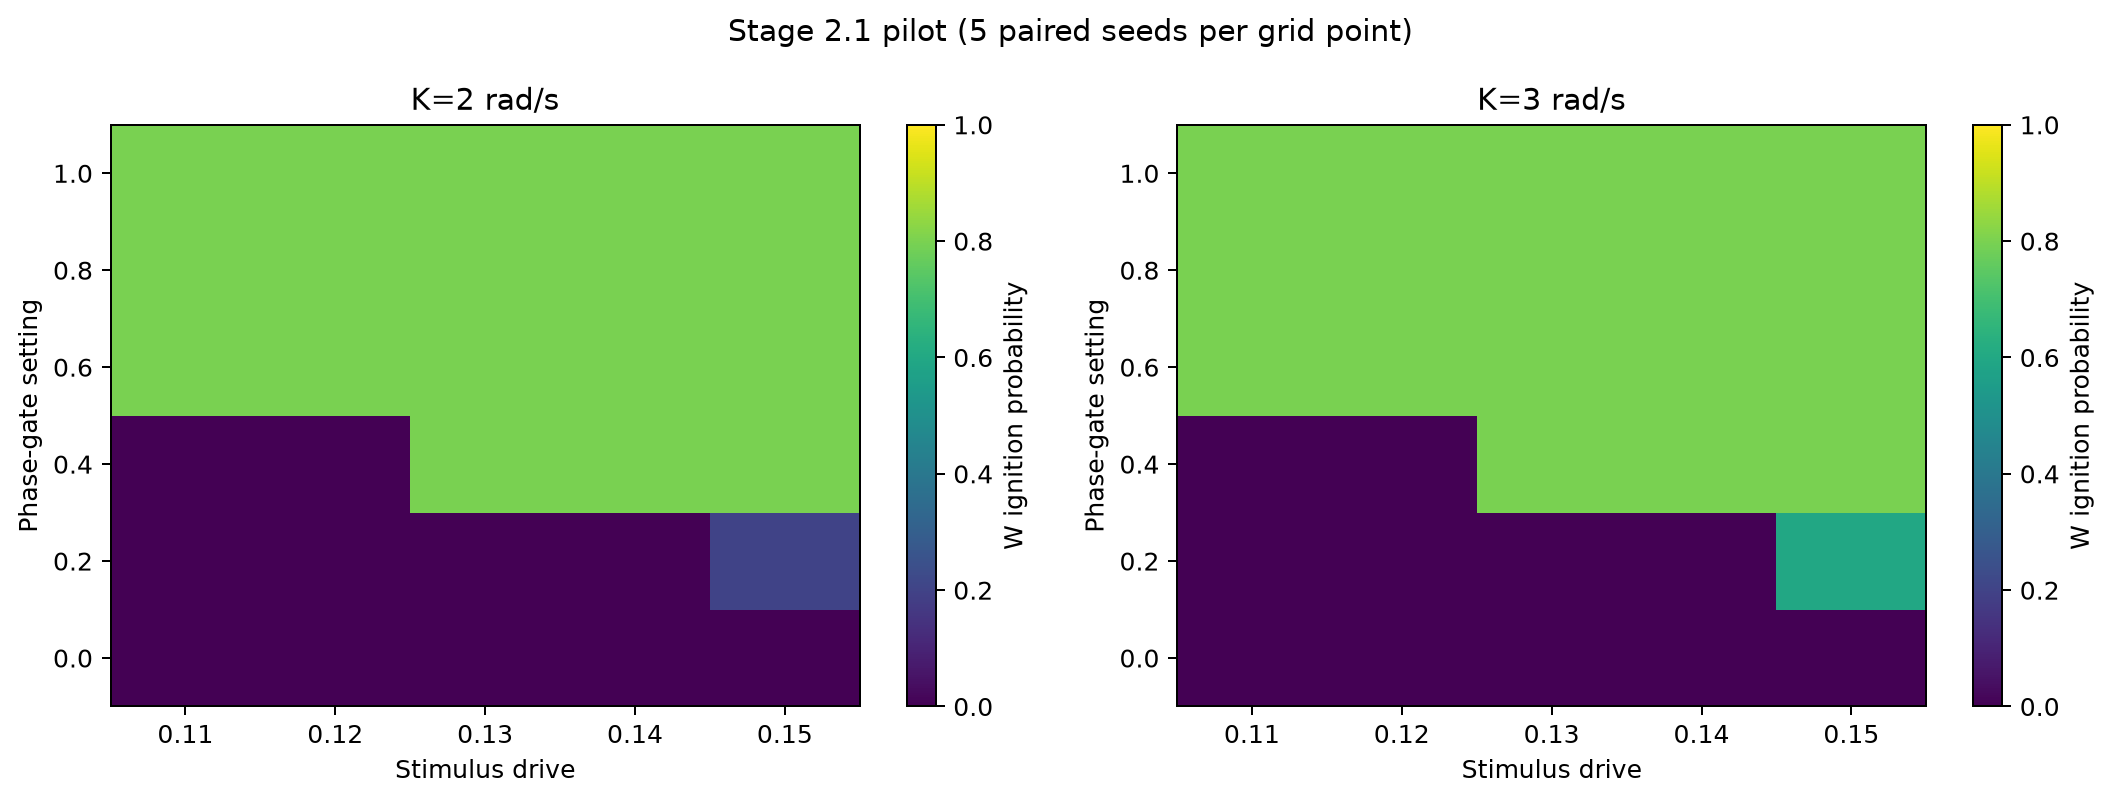

In [1]:
# Grid preview/final scan; set RUN_SCANS=True above.
if RUN_SCANS:
    drive_grid = np.round(np.arange(0.11, 0.151, 0.01), 2)  # brackets the validated 0.12–0.14 interval
    gate_grid = np.linspace(0.0, 1.0, 6)
    rows_21=[]
    from tqdm.auto import tqdm
    progress=tqdm(total=2*len(drive_grid)*len(gate_grid)*len(BASE_SEEDS),desc='Stage 2.1 pilot',unit='run')
    for K in (K_WEAK,K_STRONG):
        for drive in drive_grid:
            for gate in gate_grid:
                for seed in BASE_SEEDS:
                    res=simulate_joint(seed=int(seed),params={**BASE,'K_rad_s':K,'stimulus_drive':drive,'phase_gate_strength':gate})
                    row=one_trial_row(res,'K='+str(K),seed); row.update(stimulus_drive=drive,phase_gate_strength=gate,K_rad_s=K)
                    rows_21.append(row)
                    progress.update(1)
    progress.close()
    exp21=pd.DataFrame(rows_21)
    exp21.to_csv(OUT/'stage2_1_strength_synchrony_trials.csv',index=False)
    map21=exp21.groupby(['K_rad_s','stimulus_drive','phase_gate_strength']).agg(
        ignition_probability=('ignited','mean'),mean_R=('mean_R','mean')).reset_index()
    map21.to_csv(OUT/'stage2_1_bifurcation_summary.csv',index=False)
    display(map21.head())
    fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
    fig.suptitle(f'Stage 2.1 scan ({len(BASE_SEEDS)} seeds per grid point)')
    for ax,K in zip(axes,(K_WEAK,K_STRONG)):
        q=map21[map21.K_rad_s==K].pivot(index='phase_gate_strength',columns='stimulus_drive',values='ignition_probability')
        im=ax.imshow(q.to_numpy(),origin='lower',aspect='auto',vmin=0,vmax=1,
                     extent=[q.columns.min(),q.columns.max(),q.index.min(),q.index.max()],cmap='viridis')
        ax.set(title=f'K={K:g} rad/s',xlabel='Stimulus drive',ylabel='Phase-gate setting')
        ax.set_xticks(drive_grid); ax.set_yticks(gate_grid); ax.tick_params(axis='y',labelleft=True)
        fig.colorbar(im,ax=ax,label='W ignition probability')
    fig.tight_layout(); fig.savefig(OUT/'stage2_1_bifurcation_maps.png',dpi=180,bbox_inches='tight'); plt.show()
else:
    print('Set RUN_SCANS=True and run this cell to execute Experiment 2.1.')


### Stage 2.1 pilot readout (5 seeds; preliminary only)

The pilot produced a clear phase-gate effect: at gate setting 0, no grid point ignited; at 0.4, ignition appeared mainly for drive ≥0.13; at 0.6–1.0, 4/5 seeds ignited across most of the scanned drive range. K=3 showed a modest advantage over K=2 near the boundary (for example, at gate=0.2 and drive=0.15, 3/5 vs 1/5 ignited). Mean PLV was essentially unchanged by the gate setting because this model applies the gate to transmission, not to the phase equations.

With only 5 seeds, rates change in 20-point increments and one non-igniting seed strongly shapes the map. Treat this as a code/mechanism preview, not a confirmed boundary. The final scan should use at least 50 paired seeds and inspect the boundary around gate=0.2–0.6 and drive=0.12–0.15.


## Experiment 2.2 — attention gain and boundary shifts

The ablation compares `intensity` (g_task scales stimulus), `synchrony` (g_task scales K), and `both`. The resulting heatmaps show how the ignition boundary moves with task gain. This is a model-defined decomposition, not a claim that biological attention has only these two channels.

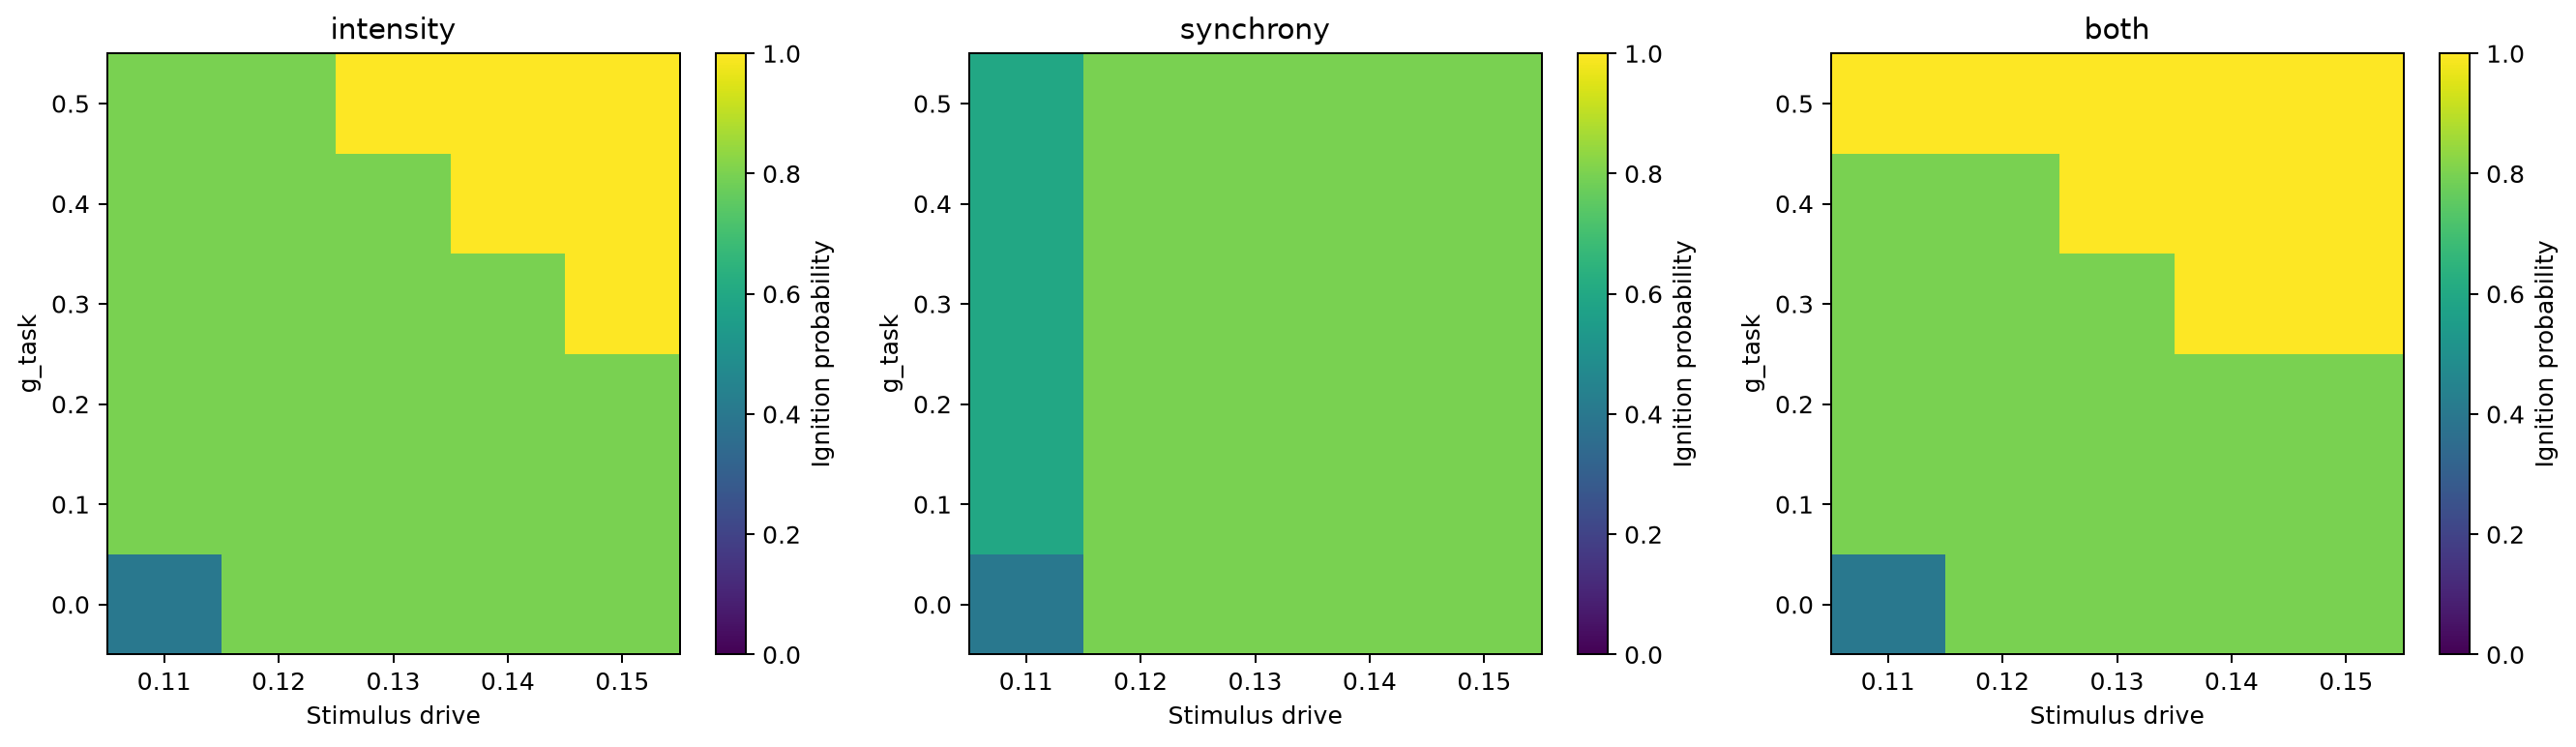

In [1]:
if RUN_SCANS:
    task_grid=np.linspace(0.0,0.5,6); drive_grid_22=np.round(np.arange(0.11,0.151,0.01),2)
    modes=('intensity','synchrony','both'); rows_22=[]
    from tqdm.auto import tqdm
    progress=tqdm(total=len(modes)*len(task_grid)*len(drive_grid_22)*len(BASE_SEEDS),desc='Stage 2.2 pilot',unit='run')
    for mode in modes:
        for gain in task_grid:
            for drive in drive_grid_22:
                for seed in BASE_SEEDS:
                    res=simulate_joint(seed=int(seed),params={**BASE,'K_rad_s':2.5,'stimulus_drive':drive,'task_gain':gain},attention_mode=mode)
                    row=one_trial_row(res,mode,seed); row.update(stimulus_drive=drive,task_gain=gain,attention_mode=mode)
                    rows_22.append(row); progress.update(1)
    progress.close()
    exp22=pd.DataFrame(rows_22); exp22.to_csv(OUT/'stage2_2_attention_ablation_trials.csv',index=False)
    map22=exp22.groupby(['attention_mode','task_gain','stimulus_drive']).agg(
        ignition_probability=('ignited','mean'),mean_R=('mean_R','mean')).reset_index()
    map22.to_csv(OUT/'stage2_2_attention_ablation_summary.csv',index=False)
    fig,axes=plt.subplots(1,3,figsize=(15,4.4),sharey=True)
    for ax,mode in zip(axes,modes):
        q=map22[map22.attention_mode==mode].pivot(index='task_gain',columns='stimulus_drive',values='ignition_probability')
        im=ax.imshow(q.to_numpy(),origin='lower',aspect='auto',vmin=0,vmax=1,
                     extent=[q.columns.min(),q.columns.max(),q.index.min(),q.index.max()],cmap='viridis')
        ax.set(title=mode,xlabel='Stimulus drive',ylabel='g_task')
        ax.set_xticks(drive_grid_22); ax.set_yticks(task_grid); ax.tick_params(axis='y',labelleft=True)
        fig.colorbar(im,ax=ax,label='Ignition probability')
    fig.tight_layout(); fig.savefig(OUT/'stage2_2_attention_ablation.png',dpi=180,bbox_inches='tight'); plt.show()
else:
    print('Set RUN_SCANS=True and run this cell to execute Experiment 2.2.')


### 2.2 pilot readout (5 seeds)

Across 450 runs, all three attention modes produced high ignition rates through much of the grid. Intensity-only and both-channel conditions reached 100% at several high-gain/high-drive cells; synchrony-only reached at most 80%. This suggests attention gain can shift the boundary, but the current grid is partly ceiling-limited and five seeds give coarse 20% steps. For a final scan, narrow stimulus values around the transition and use at least 50 paired seeds. Peak W rate stayed below 46 Hz in this pilot.


## Experiment 2.3 — recurrent gain α and hysteresis

For each α, the stimulus is ramped up and then down while the network state is carried continuously across plateaus. The onset and offset thresholds are the first/last plateau whose final 30 ms mean W rate crosses the ignition threshold. Hysteresis width = onset threshold − offset threshold. No loop (or no switch-off) is reported as zero/undefined rather than forced to look hysteretic.

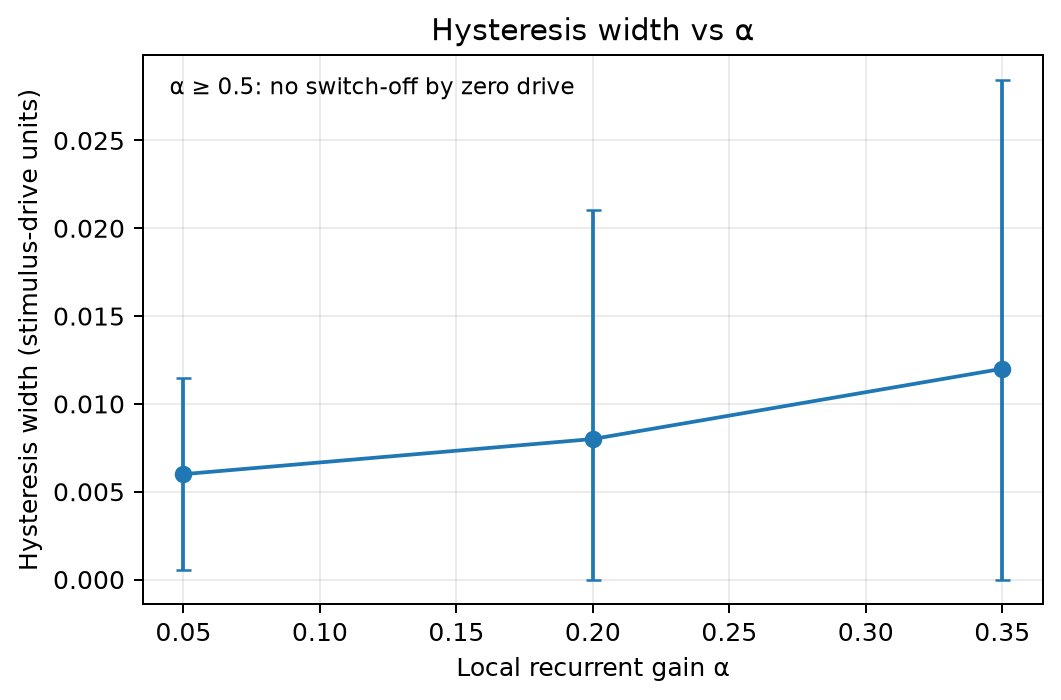

In [1]:
def make_up_down_schedule(levels, dwell_ms=80, dt_ms=1.0):
    up=np.repeat(np.asarray(levels,float),int(round(dwell_ms/dt_ms)))
    down=np.repeat(np.asarray(levels,float)[::-1],int(round(dwell_ms/dt_ms)))
    return np.concatenate([up,down])


def ramp_switch_points(result, levels, dwell_ms=80):
    dt=float(result['parameters']['dt_ms']); n=int(round(dwell_ms/dt)); rates=result['r_w_hz']
    tail=max(1,int(round(30/dt)))
    means_up=[]; means_down=[]
    for j in range(len(levels)):
        means_up.append(float(rates[j*n+n-tail:(j+1)*n].mean()))
        start=(len(levels)+j)*n
        means_down.append(float(rates[start+n-tail:start+n].mean()))
    on=[levels[j] for j,x in enumerate(means_up) if x>=BASE['ignition_threshold_hz']]
    down_levels=np.asarray(levels,float)[::-1]
    off=[down_levels[j] for j,x in enumerate(means_down) if x<BASE['ignition_threshold_hz']]
    onset=min(on) if on else np.nan
    offset=max(off) if off else np.nan
    width=onset-offset if np.isfinite(onset) and np.isfinite(offset) else np.nan
    return onset,offset,width,means_up,means_down

if RUN_SCANS:
    alpha_grid=[0.05,0.2,0.35,0.5,0.7,0.9]
    levels=np.round(np.arange(0.0,0.201,0.01),2); schedule=make_up_down_schedule(levels)
    rows_23=[]
    from tqdm.auto import tqdm
    progress=tqdm(total=len(alpha_grid)*len(BASE_SEEDS),desc='Stage 2.3 pilot',unit='run')
    for alpha in alpha_grid:
        for seed in BASE_SEEDS:
            res=simulate_joint(seed=int(seed),params={**BASE,'alpha':alpha,'stim_on_ms':0.0,'stim_off_ms':1e9,
                'ignition_after_ms':0.0,'stimulus_drive':0.0},stimulus_schedule=schedule)
            on,off,width,_,_=ramp_switch_points(res,levels)
            rows_23.append({'seed':int(seed),'alpha':alpha,'onset_drive':on,'offset_drive':off,'hysteresis_width':width}); progress.update(1)
    progress.close()
    exp23=pd.DataFrame(rows_23); exp23.to_csv(OUT/'stage2_3_hysteresis_trials.csv',index=False)
    hysteresis=exp23.groupby('alpha').agg(mean_onset=('onset_drive','mean'),mean_offset=('offset_drive','mean'),
        mean_width=('hysteresis_width','mean'),sd_width=('hysteresis_width','std')).reset_index()
    hysteresis.to_csv(OUT/'stage2_3_hysteresis_summary.csv',index=False)
    display(hysteresis)
    fig,ax=plt.subplots(figsize=(6,4))
    finite=hysteresis.mean_width.notna()
    lower=np.minimum(hysteresis.loc[finite,'sd_width'].fillna(0),hysteresis.loc[finite,'mean_width'])
    upper=hysteresis.loc[finite,'sd_width'].fillna(0)
    ax.errorbar(hysteresis.loc[finite,'alpha'],hysteresis.loc[finite,'mean_width'],yerr=np.vstack([lower,upper]),marker='o',capsize=3)
    if (~finite).any(): ax.text(.03,.96,'α ≥ 0.5: no switch-off by zero drive',transform=ax.transAxes,va='top',fontsize=9)
    ax.set(xlabel='Local recurrent gain α',ylabel='Hysteresis width (stimulus-drive units)',title='Hysteresis width vs α'); ax.grid(alpha=.25)
    fig.tight_layout(); fig.savefig(OUT/'stage2_3_hysteresis_vs_alpha.png',dpi=180,bbox_inches='tight'); plt.show()
else:
    print('Set RUN_SCANS=True and run this cell to execute Experiment 2.3.')


### 2.3 pilot readout (5 seeds)

After correcting the descending-ramp index mapping and extending the ramp to zero drive, finite mean hysteresis widths were about 0.006, 0.008, and 0.012 input units at α=0.05, 0.20, and 0.35. At α≥0.5 the network did not switch off even at zero stimulus; these are censored/persistent states, not finite hysteresis widths. The pilot suggests a transition near α=0.35–0.5, but needs a finer α scan and more seeds.


## Experiment 2.4 — ignition latency vs phase-locking speed\n\nHold stimulus above threshold and compare K values, including a pure intensity-driven control (`phase_on=False`, no phase gate). Phase-lock acquisition is defined by a 100-ms unwrapped phase-difference slope below 0.75 rad/s, sustained for 100 ms; this avoids the startup bias of short-window PLV. Report the fraction of trials that lock as well as latency among those that do. This operational threshold should be sensitivity-tested.\n

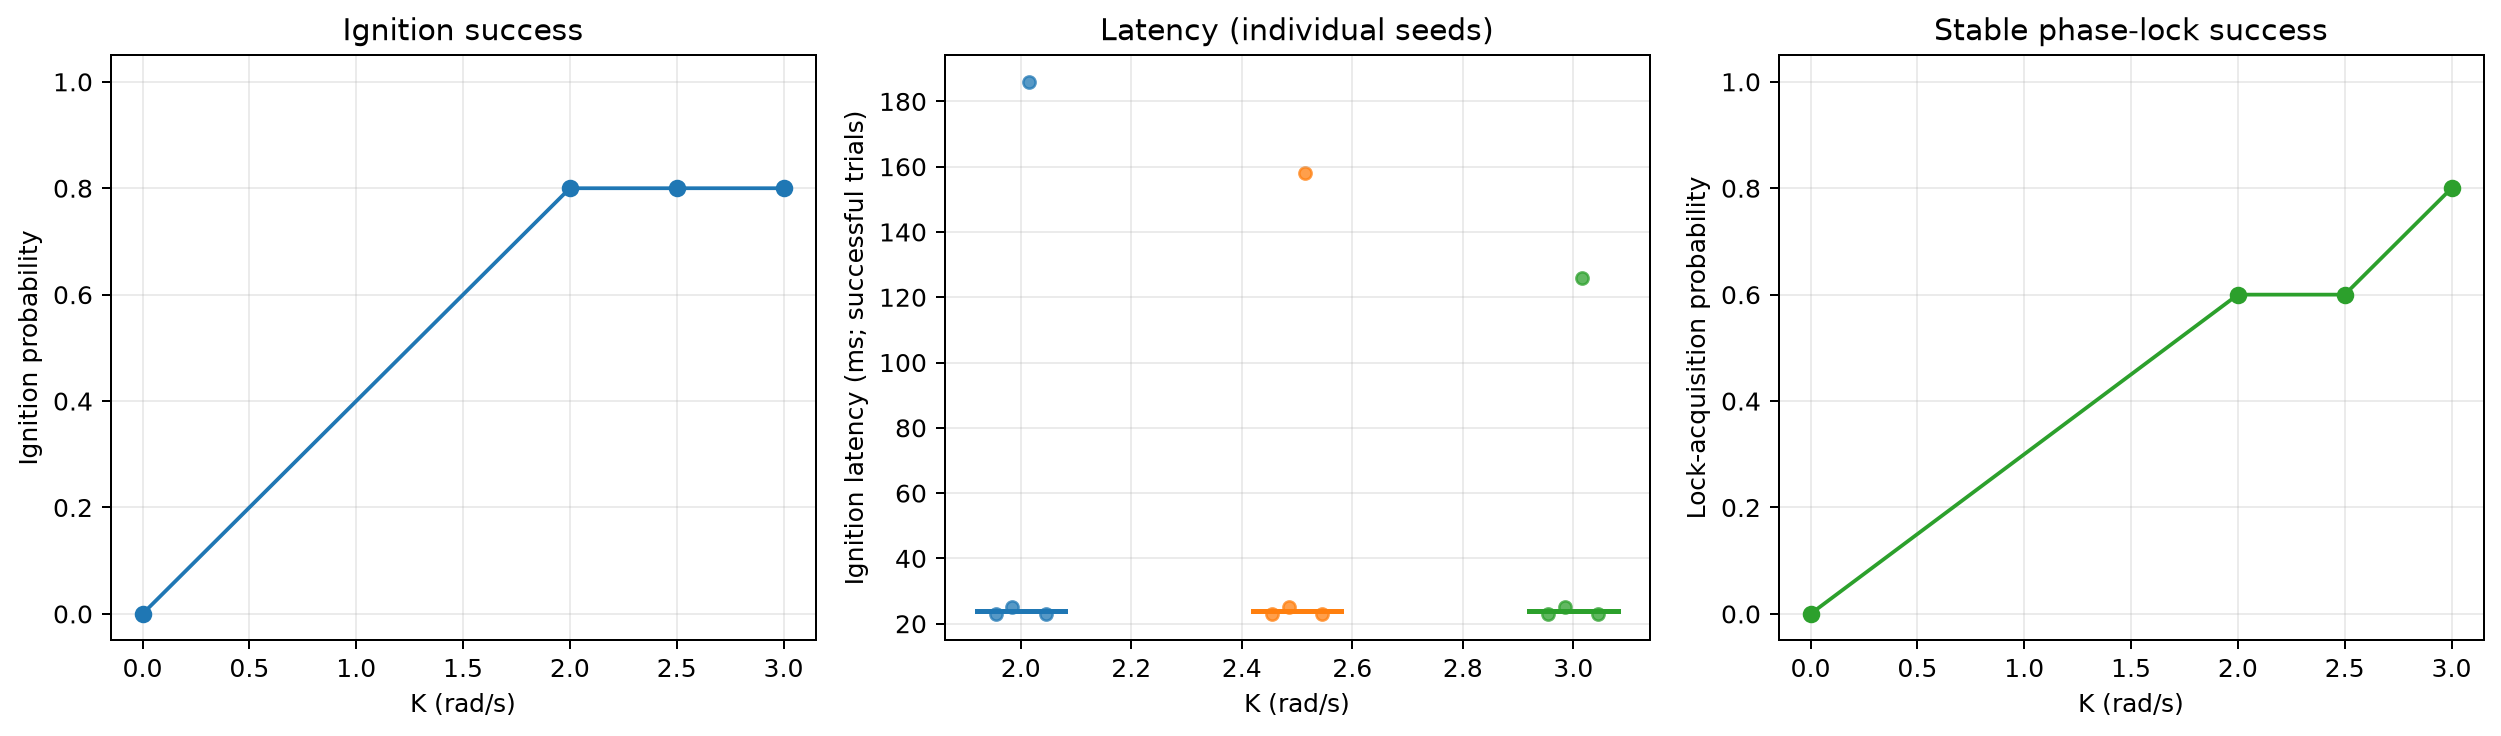

In [1]:
if RUN_SCANS:
    delay_K=[0.0,2.0,2.5,3.0]; rows_24=[]
    from tqdm.auto import tqdm
    progress=tqdm(total=len(delay_K)*len(BASE_SEEDS),desc='Stage 2.4 pilot',unit='run')
    for K in delay_K:
        phase_on=K>0
        for seed in BASE_SEEDS:
            gate=0.0 if not phase_on else BASE['phase_gate_strength']
            res=simulate_joint(seed=int(seed),params={**BASE,'stimulus_drive':0.14,'K_rad_s':K,'phase_gate_strength':gate},phase_on=phase_on)
            rows_24.append({'seed':int(seed),'K_rad_s':K,'condition':'coupled' if phase_on else 'no_phase_control',
                'ignited':res['ignited'],'ignition_latency_ms':res['ignition_latency_ms'],
                'phase_lock_latency_ms':res['phase_lock_latency_ms'],'phase_lock_time_ms':res['phase_lock_time_ms'],'mean_R':float(abs(np.exp(1j*res['delta_phase'][50:500]).mean()))}); progress.update(1)
    progress.close()
    exp24=pd.DataFrame(rows_24); exp24.to_csv(OUT/'stage2_4_latency_vs_locking_trials.csv',index=False)
    delay_summary=exp24.groupby(['condition','K_rad_s']).agg(ignition_probability=('ignited','mean'),
        mean_ignition_latency_ms=('ignition_latency_ms','mean'),sd_ignition_latency_ms=('ignition_latency_ms','std'),
        phase_lock_probability=('phase_lock_time_ms',lambda x:x.notna().mean()),mean_lock_latency_ms=('phase_lock_latency_ms','mean'),mean_lock_time_ms=('phase_lock_time_ms','mean'),mean_R=('mean_R','mean')).reset_index()
    delay_summary.to_csv(OUT/'stage2_4_latency_summary.csv',index=False)
    display(delay_summary)
    fig,axes=plt.subplots(1,3,figsize=(14,4.2))
    all_k=sorted(exp24.K_rad_s.unique())
    ignp=exp24.groupby('K_rad_s').ignited.mean().reindex(all_k)
    axes[0].plot(all_k,ignp,'o-'); axes[0].set(xlabel='K (rad/s)',ylabel='Ignition probability',ylim=(-.05,1.05),title='Ignition success')
    coupled=exp24[exp24.condition=='coupled']
    for xk,group in coupled.groupby('K_rad_s'):
        ys=group.ignition_latency_ms.dropna().to_numpy()
        if ys.size:
            jitter=np.linspace(-.045,.045,ys.size) if ys.size>1 else np.array([0.0])
            axes[1].scatter(np.full(ys.size,xk)+jitter,ys,s=24,alpha=.75)
            axes[1].plot([xk-.08,xk+.08],[np.median(ys)]*2,lw=2)
    axes[1].set(xlabel='K (rad/s)',ylabel='Ignition latency (ms; successful trials)',title='Latency (individual seeds)')
    lockp=exp24.groupby('K_rad_s').phase_lock_time_ms.apply(lambda x:x.notna().mean()).reindex(all_k)
    axes[2].plot(all_k,lockp,'o-',color='tab:green'); axes[2].set(xlabel='K (rad/s)',ylabel='Lock-acquisition probability',ylim=(-.05,1.05),title='Stable phase-lock success')
    for ax in axes: ax.grid(alpha=.25)
    fig.tight_layout(); fig.savefig(OUT/'stage2_4_latency_vs_K.png',dpi=180,bbox_inches='tight'); plt.show()
else:
    print('Set RUN_SCANS=True and run this cell to execute Experiment 2.4.')


### 2.4 pilot readout (5 seeds)

Using only the validated K range, ignition probability was 0.8 at K=2, 2.5, and 3; the no-phase control had 0/5 ignitions. Mean successful-trial ignition latency decreased from about 64.3 ms at K=2 to 49.3 ms at K=3. Under the sustained phase-difference slope criterion, lock acquisition occurred in 3/5, 3/5, and 4/5 trials, respectively; no control trials locked. These are preliminary trends from five seeds, and lock latency depends on the chosen operational criterion.


## Experiment 2.5 — three attention-decay mechanisms

The scenarios share the same initial gain and task drive: (A) gain decays exponentially after the target reaches ignition; (B) a competitor appears and reduces gain according to the un-suppressed competitor fraction; (C) gain decays with accumulated time spent above ignition threshold. The plotted gain trace makes the implemented mechanism visible.

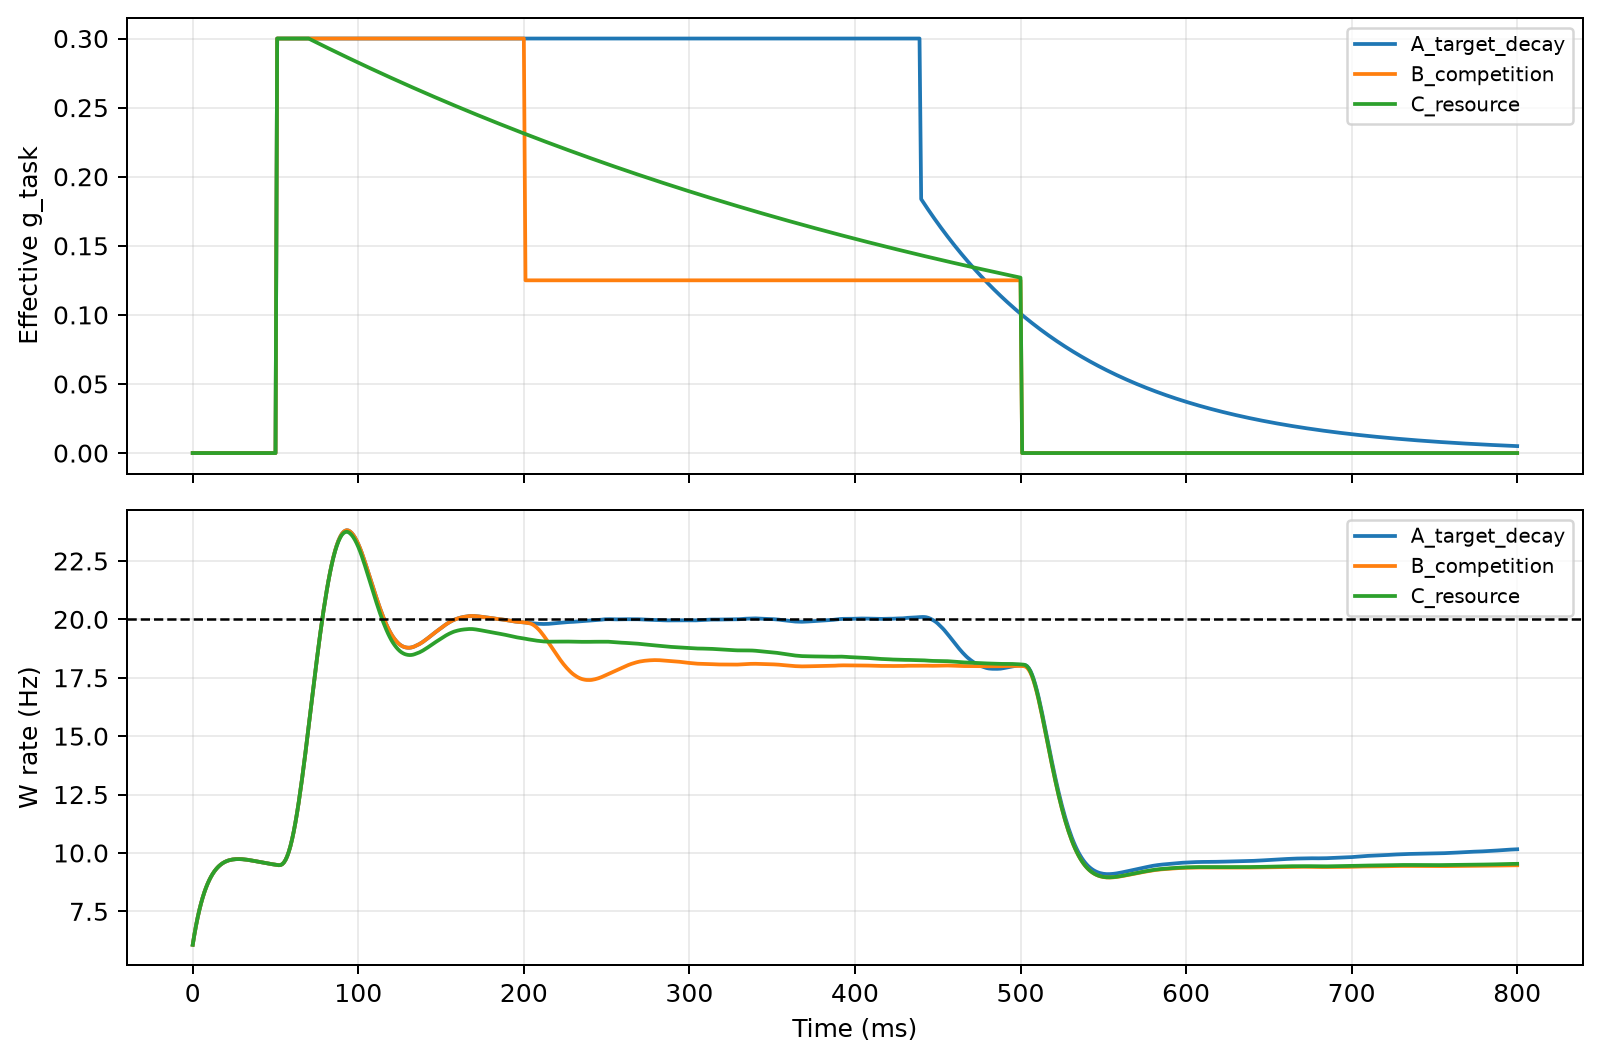

In [1]:
if RUN_SCANS:
    decay_scenarios={
        'A_target_decay':{'decay_mode':'target_decay','task_decay_tau_ms':100.0},
        'B_competition':{'decay_mode':'competition','competitor_on_ms':200.0,'competitor_level':2.0,'competition_inhibition':0.3},
        'C_resource':{'decay_mode':'resource','resource_depletion_per_s':2.0},
    }
    rows_25=[]; example_traces={}
    from tqdm.auto import tqdm
    progress=tqdm(total=len(decay_scenarios)*len(BASE_SEEDS),desc='Stage 2.5 pilot',unit='run')
    for label,overrides in decay_scenarios.items():
        for seed in BASE_SEEDS:
            res=simulate_joint(seed=int(seed),params={**BASE,'stimulus_drive':0.14,'task_gain':0.3,**overrides},decay_mode=overrides['decay_mode'])
            row=one_trial_row(res,label,seed); rows_25.append(row)
            if seed==BASE_SEEDS[0]: example_traces[label]=res
            progress.update(1)
    progress.close()
    exp25=pd.DataFrame(rows_25); exp25.to_csv(OUT/'stage2_5_attention_decay_trials.csv',index=False)
    summary25=exp25.groupby('condition').agg(ignition_probability=('ignited','mean'),mean_latency_ms=('latency_ms','mean'),latency_variance_ms2=('latency_ms','var'),mean_W_after_hz=('mean_W_after_hz','mean'),mean_above_threshold_after_ms=('W_above_threshold_after_ms','mean')).reset_index()
    summary25.to_csv(OUT/'stage2_5_attention_decay_summary.csv',index=False)
    display(summary25)
    fig,axes=plt.subplots(2,1,figsize=(9,6),sharex=True)
    for label,res in example_traces.items():
        axes[0].plot(res['time_ms'],res['g_task'],label=label)
        axes[1].plot(res['time_ms'],res['r_w_hz'],label=label)
    axes[0].set_ylabel('Effective g_task'); axes[1].set_ylabel('W rate (Hz)'); axes[1].set_xlabel('Time (ms)')
    axes[1].axhline(BASE['ignition_threshold_hz'],color='k',ls='--',lw=1)
    for ax in axes: ax.grid(alpha=.25); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUT/'stage2_5_attention_decay.png',dpi=180,bbox_inches='tight'); plt.show()
else:
    print('Set RUN_SCANS=True and run this cell to execute Experiment 2.5.')


### 2.5 pilot readout (5 seeds)

The three mechanisms produce distinct g_task trajectories: target-triggered decay, competitor-related reduction, and gradual resource depletion. Initial ignition remained common (0.8–1.0 probability), but post-stimulus W rates returned near baseline (about 11.7 Hz on average); this pilot therefore did not show late sustained ignition. The resource mechanism now accumulates activity above 15 Hz rather than resetting at every brief threshold dip.


## Experiment 2.6 — ADHD-inspired parameter perturbations

These are model perturbations, not a clinical diagnosis or a claim that ADHD has one parameter signature. The baseline uses K=3 and task gain 0.25; each perturbation changes one factor: lower task gain, slower phase coupling (K=2, still inside the replicated range), or weaker suppression of a distractor. The combined condition changes all three. Use 50–100 seeds and report ignition probability plus latency variance among successful trials.

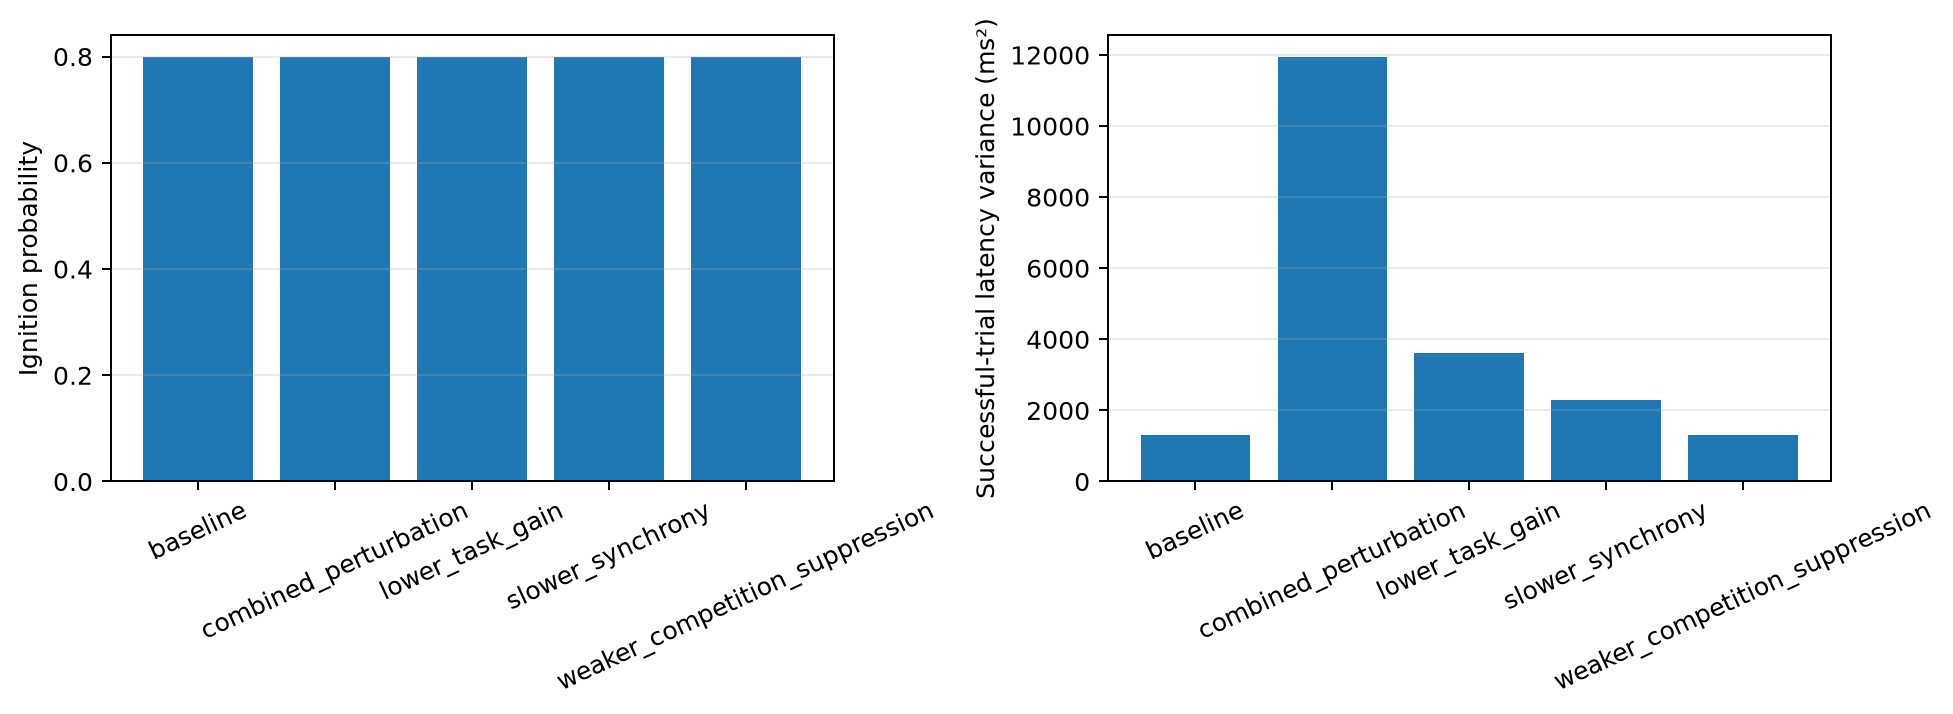

In [1]:
if RUN_SCANS:
    adhd_conditions={
        'baseline':{'task_gain':0.25,'K_rad_s':3.0,'competition_inhibition':0.8},
        'lower_task_gain':{'task_gain':0.10,'K_rad_s':3.0,'competition_inhibition':0.8},
        'slower_synchrony':{'task_gain':0.25,'K_rad_s':2.0,'competition_inhibition':0.8},
        'weaker_competition_suppression':{'task_gain':0.25,'K_rad_s':3.0,'competition_inhibition':0.3},
        'combined_perturbation':{'task_gain':0.10,'K_rad_s':2.0,'competition_inhibition':0.3},
    }
    rows_26=[]
    from tqdm.auto import tqdm
    progress=tqdm(total=len(adhd_conditions)*len(BASE_SEEDS),desc='Stage 2.6 pilot',unit='run')
    for label,overrides in adhd_conditions.items():
        for seed in BASE_SEEDS:
            res=simulate_joint(seed=int(seed),params={**BASE,'stimulus_drive':0.12,'competitor_on_ms':200.0,
                'competitor_level':1.0,'decay_mode':'competition',**overrides},decay_mode='competition')
            row=one_trial_row(res,label,seed); row['K_rad_s']=overrides['K_rad_s']; row['task_gain']=overrides['task_gain'];
            row['competition_inhibition']=overrides['competition_inhibition']; rows_26.append(row); progress.update(1)
    progress.close()
    exp26=pd.DataFrame(rows_26); exp26.to_csv(OUT/'stage2_6_adhd_parameter_map_trials.csv',index=False)
    def _latency_var_success(x):
        y=x.dropna().to_numpy(float)
        return float(np.var(y,ddof=1)) if y.size>1 else np.nan
    adhd_summary=exp26.groupby('condition').agg(n=('seed','count'),ignition_probability=('ignited','mean'),
        mean_latency_ms=('latency_ms','mean'),latency_variance_success_ms2=('latency_ms',_latency_var_success),
        mean_peak_W_hz=('peak_W_hz','mean')).reset_index()
    display(adhd_summary)
    adhd_summary.to_csv(OUT/'stage2_6_adhd_parameter_map_summary.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    axes[0].bar(adhd_summary.condition,adhd_summary.ignition_probability); axes[0].set_ylabel('Ignition probability'); axes[0].tick_params(axis='x',rotation=25)
    axes[1].bar(adhd_summary.condition,adhd_summary.latency_variance_success_ms2); axes[1].set_ylabel('Successful-trial latency variance (ms²)'); axes[1].tick_params(axis='x',rotation=25)
    for ax in axes: ax.grid(axis='y',alpha=.25)
    fig.tight_layout(); fig.savefig(OUT/'stage2_6_adhd_summary.png',dpi=180,bbox_inches='tight'); plt.show()
else:
    print('Set RUN_SCANS=True and run this cell to execute Experiment 2.6.')


### 2.6 pilot readout (5 seeds)

All five conditions ignited in 4/5 seeds. Mean successful-trial latency was 40 ms in baseline, 55 ms with lower task gain, 46 ms with K reduced from 3 to 2, and 40 ms with weaker competition suppression; the combined perturbation averaged 80 ms. The combined condition had the largest successful-trial latency variance (~11,955 ms²), versus ~1,297 ms² at baseline. With only four successful trials per condition, these variance estimates are too noisy for conclusions; repeat with 50–100 paired seeds.


## Reading the outputs and decision rules

1. **2.1:** ignition boundaries should shift with gate setting and differ between K=2 and K=3. Check mean PLV as a manipulation readout; do not equate phase-gate setting with observed synchrony.
2. **2.2:** compare the three attention ablations at matched stimulus and gain. A boundary shift in `both` alone suggests an interaction; compare it with intensity-only and synchrony-only.
3. **2.3:** hysteresis requires distinct up- and down-switch points and should grow with α before runaway activity. Inspect peak W rates as well; a permanently high-rate state is not a useful GNW ignition result.
4. **2.4:** latency should be compared only among trials that ignite. Report ignition probability alongside latency to avoid survivorship bias. The no-phase control can have undefined locking latency.
5. **2.5:** confirm that the gain traces implement the intended three mechanisms and distinguish their effects on post-onset persistence.
6. **2.6:** compare paired seeds, ignition probability, latency variance among successful trials, and peak rate. The `combined_perturbation` is exploratory; do not interpret these settings as a validated ADHD biomarker.

Every scan writes CSV/PNG files to `project_experiment/`. Start with preview seeds, inspect the boundary and stability, then increase to 50–100 seeds for final Monte Carlo estimates.